# Exploratory Data Analysis — Online Retail (UK e-commerce, 2010–2011)

**Dataset:** [E-Commerce Data on Kaggle](https://www.kaggle.com/datasets/carrie1/ecommerce-data), originally from the
[UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (Chen, Sain & Guo, 2012).
Every transaction of a UK-based online gift retailer between **01-Dec-2010 and 09-Dec-2011**. Many of its customers are wholesalers.

| Column | Meaning |
|---|---|
| InvoiceNo | invoice number. A leading **C** means a cancellation |
| StockCode | product code |
| Description | product name |
| Quantity | units per line |
| InvoiceDate | date and time |
| UnitPrice | price per unit (GBP) |
| CustomerID | customer number |
| Country | customer's country |

**Questions**
1. How clean is the data, and what has to be fixed before analysis?
2. How do sales move over time (month, weekday, hour)?
3. Which countries, products and customers drive revenue? How concentrated is it?
4. How do customer-level variables relate to each other (recency, frequency, spend, basket size)?
5. How well are customers retained, and what gets returned?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colour roles (validated categorical palette + one-hue sequential ramp for magnitude)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, MUTED, INK = SERIES[0], SERIES[1], "#b9b8b2", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 20)

FIG = Path("figures")
FIG.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")

def _gbp(v, _):
    if abs(v) >= 1e6: return f"£{v/1e6:.1f}M"
    if abs(v) >= 1e4: return f"£{v/1e3:.0f}K"
    if abs(v) >= 1e3: return f"£{v/1e3:.1f}K"
    return f"£{v:.0f}"
gbp = mtick.FuncFormatter(_gbp)

## 1. Load and first look

In [2]:
raw = pd.read_excel("data/Online Retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 33.1+ MB


In [4]:
raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


Already visible: `Quantity` and `UnitPrice` have **negative minimums** and huge maximums (±80,995 units), and `CustomerID`
was read as a float because it has missing values.

## 2. Data-quality audit

In [5]:
is_cancel = raw["InvoiceNo"].str.startswith("C")
is_product = raw["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")
desc = raw["Description"].astype("string")

audit = pd.DataFrame([
    ("Missing CustomerID",                          raw["CustomerID"].isna().sum()),
    ("Missing Description",                         raw["Description"].isna().sum()),
    ("Exact duplicate rows",                        raw.duplicated().sum()),
    ("Cancellation invoices (InvoiceNo starts 'C')", is_cancel.sum()),
    ("Quantity <= 0 on a normal invoice",           ((raw["Quantity"] <= 0) & ~is_cancel).sum()),
    ("UnitPrice <= 0",                              (raw["UnitPrice"] <= 0).sum()),
    ("Non-product StockCode (postage, fees, ...)",  (~is_product).sum()),
    ("Description with extra spaces",               (desc != desc.str.strip()).sum()),
    ("|Quantity| >= 10,000",                        (raw["Quantity"].abs() >= 10_000).sum()),
], columns=["Issue", "Rows"])
audit["% of rows"] = 100 * audit["Rows"] / len(raw)
audit

,Issue,Rows,% of rows
0,Missing CustomerID,135080,24.93
1,Missing Description,1454,0.27
2,Exact duplicate rows,5268,0.97
3,Cancellation invoices (InvoiceNo starts 'C'),9288,1.71
4,Quantity <= 0 on a normal invoice,1336,0.25
5,UnitPrice <= 0,2517,0.46
6,"Non-product StockCode (postage, fees, ...)",2995,0.55
7,Description with extra spaces,113452,20.94
8,"|Quantity| >= 10,000",5,0.00


In [6]:
# Non-product codes: what are they?
(raw.loc[~is_product].groupby("StockCode")
    .agg(Description=("Description", "first"), Rows=("InvoiceNo", "size"))
    .sort_values("Rows", ascending=False).head(12))

,Description,Rows
StockCode,,
POST,POSTAGE,1256
DOT,DOTCOM POSTAGE,710
M,Manual,571
C2,CARRIAGE,144
D,Discount,77
S,SAMPLES,63
BANK CHARGES,Bank Charges,37
AMAZONFEE,AMAZON FEE,34
CRUK,CRUK Commission,16


In [7]:
# The same StockCode is written with several descriptions (typos, renamed products)
n_desc = raw.dropna(subset=["Description"]).groupby("StockCode")["Description"].nunique()
print(f"{(n_desc > 1).sum()} stock codes have more than one description, e.g. 23196:")
raw.loc[raw["StockCode"] == "23196", "Description"].value_counts()

650 stock codes have more than one description, e.g. 23196:


Description
VINTAGE LEAF MAGNETIC NOTEPAD         285
RETRO LEAVES MAGNETIC NOTEPAD          22
RETO LEAVES MAGNETIC SHOPPING LIST      3
LEAVES MAGNETIC  SHOPPING LIST          2
Name: count, dtype: int64

In [8]:
# The two extreme orders were cancelled minutes later: data-entry errors, not real demand
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]
raw.loc[raw["Quantity"].abs() >= 70_000, cols]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"12,346.00",2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"12,346.00",2011-01-18 10:17:00
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00",2011-12-09 09:15:00
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"16,446.00",2011-12-09 09:27:00


In [9]:
# Who are the customers without an ID?
no_id = raw[raw["CustomerID"].isna() & ~is_cancel & (raw["Quantity"] > 0) & (raw["UnitPrice"] > 0)]
share_rev = (no_id["Quantity"] * no_id["UnitPrice"]).sum() / (raw.loc[~is_cancel & (raw["UnitPrice"] > 0) & (raw["Quantity"] > 0), "Quantity"]
                                                              * raw.loc[~is_cancel & (raw["UnitPrice"] > 0) & (raw["Quantity"] > 0), "UnitPrice"]).sum()
print(f"Rows without CustomerID: {raw['CustomerID'].isna().mean():.1%} of rows, but only {share_rev:.1%} of sales value")
print("Top countries of rows without CustomerID:")
no_id["Country"].value_counts(normalize=True).head(3)

Rows without CustomerID: 24.9% of rows, but only 16.5% of sales value
Top countries of rows without CustomerID:


Country
United Kingdom   0.99
EIRE             0.00
Hong Kong        0.00
Name: proportion, dtype: float64

### Cleaning decisions

| Issue | Decision | Why |
|---|---|---|
| Exact duplicates | **Remove**, before and again after name cleaning | The same line entered twice would double-count sales |
| Cancellations (`C…`) | **Move to a separate `returns` table** | They are returns, not sales. Analysed separately in section 3.9 |
| Non-product codes (POST, DOT, M, AMAZONFEE, BANK CHARGES…) | **Remove** | Postage, fees and manual adjustments are not product demand |
| Quantity ≤ 0 on normal invoices | **Remove** | Stock write-offs ("damages", "check", "?"), none have a customer |
| UnitPrice ≤ 0 | **Remove** | Free samples or bad-debt adjustments with no revenue |
| Orders fully reversed within a day (same customer, product, quantity) | **Remove both the sale and its cancellation** | Includes the 80,995- and 74,215-unit entry errors |
| Messy descriptions | **Trim, upper-case, one canonical name per StockCode** (the most frequent) | So each product is grouped under one name |
| Missing CustomerID (25% of rows) | **Keep**, flag `HasCustomer` | They carry 16.5% of sales, almost all from the UK (most likely guest checkouts). Dropping them would under-state revenue. They are left out **only** in customer-level analysis |

In [10]:
log = []
def step(name, before, after):
    log.append({"Step": name, "Rows before": len(before), "Removed": len(before) - len(after), "Rows after": len(after)})
    return after

df = step("Remove exact duplicates", raw, raw.drop_duplicates())

cancel_mask = df["InvoiceNo"].str.startswith("C")
returns = df[cancel_mask].copy()
df = step("Move cancellations to `returns`", df, df[~cancel_mask])

df = step("Remove non-product stock codes", df, df[df["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")])
df = step("Remove quantity <= 0 (stock adjustments)", df, df[df["Quantity"] > 0])
df = step("Remove unit price <= 0", df, df[df["UnitPrice"] > 0])

# Sales fully reversed by a cancellation of the same customer/product/quantity within 1 day
c = (returns.dropna(subset=["CustomerID"])
            .assign(Quantity=lambda x: -x["Quantity"])
            [["CustomerID", "StockCode", "Quantity", "InvoiceDate"]]
            .rename(columns={"InvoiceDate": "CancelDate"})
            .rename_axis("cancel_idx").reset_index())
pairs = df.reset_index().merge(c, on=["CustomerID", "StockCode", "Quantity"])
lag = pairs["CancelDate"] - pairs["InvoiceDate"]
pairs = pairs[(lag >= pd.Timedelta(0)) & (lag <= pd.Timedelta(days=1))]
df = step("Remove sales reversed within 1 day", df, df.drop(index=pairs["index"].unique()))
# ...and their cancellations, so the returns analysis does not count entry errors as returns
returns = returns.drop(index=pairs["cancel_idx"].unique())
print(f"Reversed pairs removed: {pairs['index'].nunique()} sales lines and {pairs['cancel_idx'].nunique()} cancellation lines")

# Standardise product names: trim, collapse spaces, upper-case, then one canonical name per code
clean_desc = df["Description"].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
canonical = clean_desc.groupby(df["StockCode"]).agg(lambda s: s.value_counts().idxmax())
df = df.assign(Description=df["StockCode"].map(canonical))
# rows that differed only in how the description was typed are now exact duplicates
df = step("Remove duplicates revealed by name cleaning", df, df.drop_duplicates())

# Types and derived columns
df = df.assign(
    CustomerID=df["CustomerID"].astype("Int64").astype("string"),
    HasCustomer=df["CustomerID"].notna(),
    Revenue=df["Quantity"] * df["UnitPrice"],
    Month=df["InvoiceDate"].dt.to_period("M"),
    Weekday=df["InvoiceDate"].dt.day_name(),
    Hour=df["InvoiceDate"].dt.hour,
)
returns = returns[returns["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")].assign(
    Revenue=lambda x: x["Quantity"] * x["UnitPrice"],
    CustomerID=lambda x: x["CustomerID"].astype("Int64").astype("string"))

cleaning_log = pd.DataFrame(log)
cleaning_log

Reversed pairs removed: 683 sales lines and 642 cancellation lines


,Step,Rows before,Removed,Rows after
0,Remove exact duplicates,541909,5268,536641
1,Move cancellations to `returns`,536641,9251,527390
2,Remove non-product stock codes,527390,2406,524984
3,Remove quantity <= 0 (stock adjustments),524984,1324,523660
4,Remove unit price <= 0,523660,1156,522504
5,Remove sales reversed within 1 day,522504,683,521821
6,Remove duplicates revealed by name cleaning,521821,2,521819


In [11]:
print(f"Clean sales lines : {len(df):,}  ({len(df) / len(raw):.1%} of raw rows kept)")
print(f"Invoices          : {df['InvoiceNo'].nunique():,}")
print(f"Products          : {df['StockCode'].nunique():,}")
print(f"Customers (with ID): {df['CustomerID'].nunique():,}")
print(f"Countries         : {df['Country'].nunique()}")
print(f"Revenue           : £{df['Revenue'].sum():,.0f}")
print(f"Period            : {df['InvoiceDate'].min():%d-%b-%Y} to {df['InvoiceDate'].max():%d-%b-%Y}")
assert df.duplicated().sum() == 0 and (df["Quantity"] > 0).all() and (df["UnitPrice"] > 0).all()

Clean sales lines : 521,819  (96.3% of raw rows kept)
Invoices          : 19,699
Products          : 3,899
Customers (with ID): 4,333
Countries         : 38
Revenue           : £9,909,310
Period            : 01-Dec-2010 to 09-Dec-2011


## 3. Exploratory analysis

### 3.1 Distributions: what does a typical order look like?

In [12]:
orders = df.groupby("InvoiceNo").agg(
    OrderValue=("Revenue", "sum"), Lines=("StockCode", "size"), Units=("Quantity", "sum"),
    HasCustomer=("HasCustomer", "first"), Country=("Country", "first"), InvoiceDate=("InvoiceDate", "first"))
orders[["OrderValue", "Lines", "Units"]].describe(percentiles=[.25, .5, .75, .95, .99])

,OrderValue,Lines,Units
count,"19,699.00","19,699.00","19,699.00"
mean,503.04,26.49,272.95
std,"1,141.21",47.39,558.28
min,0.38,1.00,1.00
25%,151.88,7.00,71.00
50%,302.20,15.00,152.00
75%,480.94,29.00,297.00
95%,"1,495.28",77.00,804.10
99%,"4,391.34",219.00,"2,224.10"
max,"52,940.94","1,112.00","15,049.00"


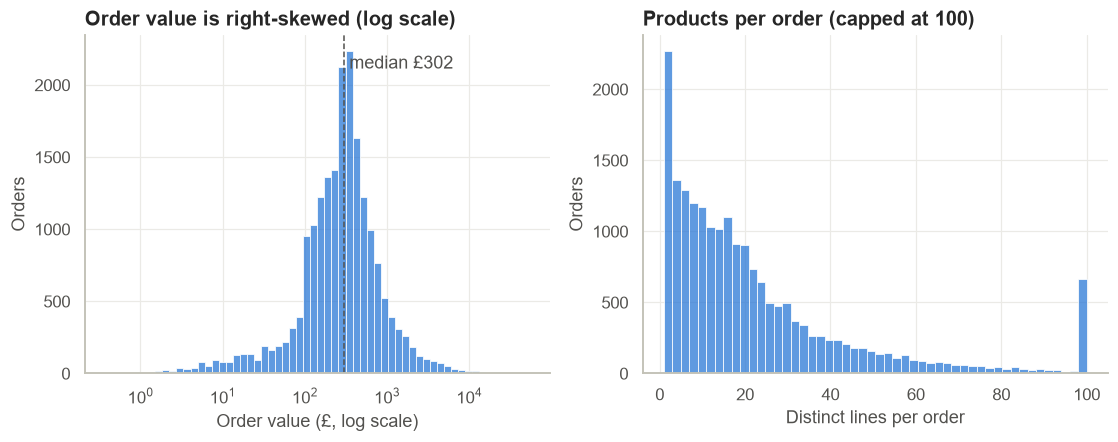

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders["OrderValue"], bins=60, log_scale=True, color=BLUE, edgecolor="white", linewidth=0.5, ax=axes[0])
med = orders["OrderValue"].median()
axes[0].axvline(med, color=INK, ls="--", lw=1)
axes[0].text(med * 1.15, axes[0].get_ylim()[1] * 0.9, f"median £{med:,.0f}", color=INK)
axes[0].set(title="Order value is right-skewed (log scale)", xlabel="Order value (£, log scale)", ylabel="Orders")

sns.histplot(orders["Lines"].clip(upper=100), bins=50, color=BLUE, edgecolor="white", linewidth=0.5, ax=axes[1])
axes[1].set(title="Products per order (capped at 100)", xlabel="Distinct lines per order", ylabel="Orders")
save(fig, "01_distributions")
plt.show()

Order values are strongly right-skewed. The **median (not the mean)** is the right "typical order" here. A long tail of large
orders, a few thousand pounds each, comes from wholesale buyers. Because of this skew the analysis below uses log scales,
medians and rank-based (Spearman) correlation.

### 3.2 Trend over time

In [14]:
monthly = df.groupby("Month").agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique"),
                                  Customers=("CustomerID", "nunique"))
monthly["AOV"] = monthly["Revenue"] / monthly["Orders"]
monthly["Days"] = df.groupby("Month")["InvoiceDate"].apply(lambda s: s.dt.date.nunique())
monthly

,Revenue,Orders,Customers,AOV,Days
Month,,,,,
2010-12,"771,874.55",1545,884,499.60,20
2011-01,"590,832.33",1077,738,548.59,24
2011-02,"507,574.05",1089,756,466.09,24
2011-03,"686,294.46",1435,972,478.25,27
2011-04,"513,545.40",1228,852,418.20,21
2011-05,"739,712.82",1664,1054,444.54,25
2011-06,"696,493.51",1517,988,459.13,26
2011-07,"686,680.30",1449,945,473.90,26
2011-08,"719,610.04",1337,933,538.23,26


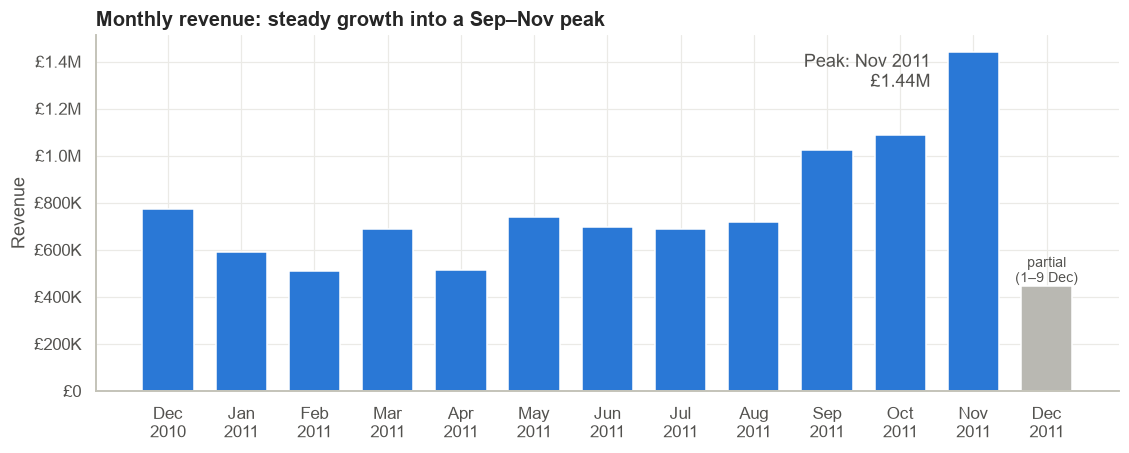

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.2))
labels = monthly.index.strftime("%b\n%Y")
colors = [MUTED if m == pd.Period("2011-12") else BLUE for m in monthly.index]
ax.bar(labels, monthly["Revenue"], color=colors, width=0.7)
ax.yaxis.set_major_formatter(gbp)
peak = monthly["Revenue"].idxmax()
ax.text(list(monthly.index).index(peak) - 0.45, monthly.loc[peak, "Revenue"],
        f"Peak: {peak.strftime('%b %Y')}  \n£{monthly.loc[peak, 'Revenue']/1e6:.2f}M  ", ha="right", va="top", color=INK)
ax.text(len(monthly) - 1, monthly["Revenue"].iloc[-1], "partial\n(1–9 Dec)", ha="center", va="bottom", color=INK, fontsize=9)
ax.set(title="Monthly revenue: steady growth into a Sep–Nov peak", ylabel="Revenue")
save(fig, "02_monthly_revenue")
plt.show()

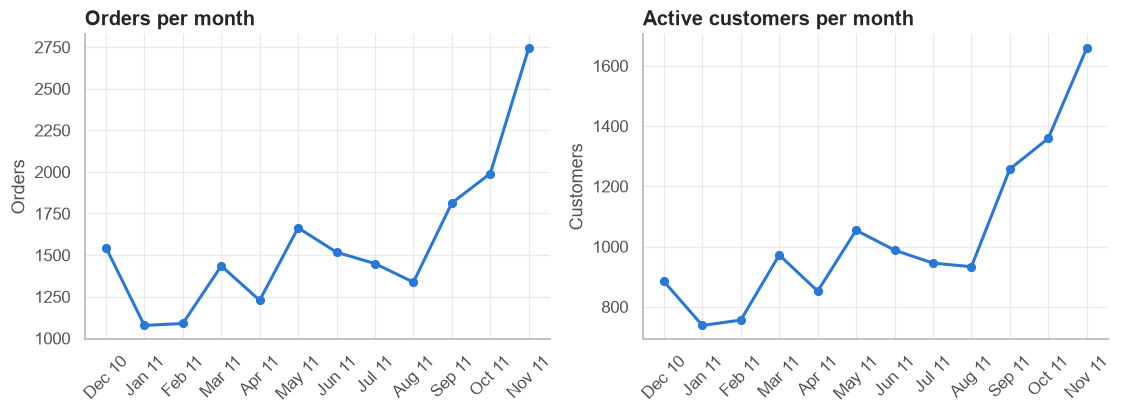

Nov-2011 vs Dec-2010: revenue +87%, orders +78%, customers +88%, AOV +5%
Sep-Nov 2011 = 35.8% of all revenue in the dataset


In [16]:
# Orders and customers on separate panels (different scales -> no dual axis)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
full = monthly.loc[:"2011-11"]
for ax, col, title in [(axes[0], "Orders", "Orders per month"), (axes[1], "Customers", "Active customers per month")]:
    ax.plot(full.index.strftime("%b %y"), full[col], color=BLUE, marker="o", markersize=5)
    ax.set(title=title, ylabel=col)
    ax.tick_params(axis="x", rotation=45)
save(fig, "03_orders_customers")
plt.show()

nov, dec10 = monthly.loc["2011-11"], monthly.loc["2010-12"]
print(f"Nov-2011 vs Dec-2010: revenue {nov.Revenue / dec10.Revenue - 1:+.0%}, orders {nov.Orders / dec10.Orders - 1:+.0%}, "
      f"customers {nov.Customers / dec10.Customers - 1:+.0%}, AOV {nov.AOV / dec10.AOV - 1:+.0%}")
q4 = monthly.loc["2011-09":"2011-11", "Revenue"].sum() / monthly["Revenue"].sum()
print(f"Sep-Nov 2011 = {q4:.1%} of all revenue in the dataset")

### 3.3 When do customers buy? (weekday × hour)

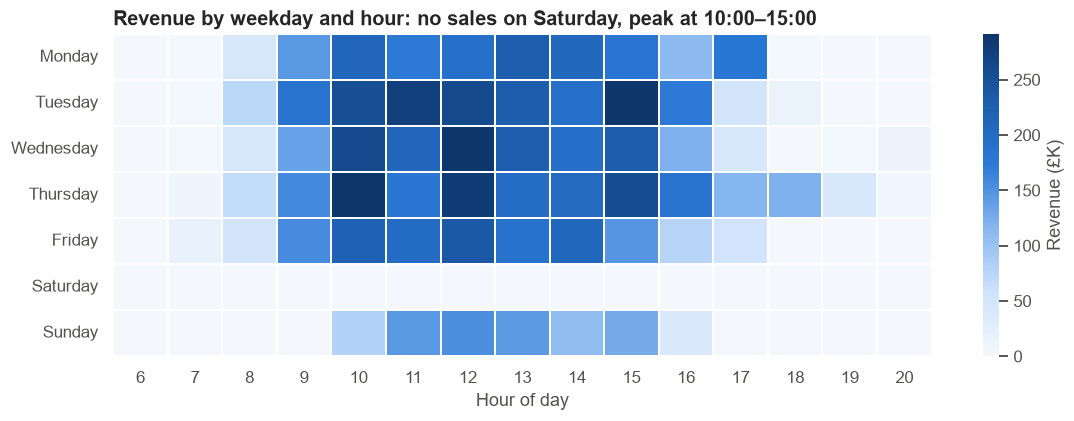

,Share of revenue
Weekday,
Monday,0.17
Tuesday,0.20
Wednesday,0.18
Thursday,0.21
Friday,0.16
Saturday,0.00
Sunday,0.08


In [17]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (df.pivot_table(index="Weekday", columns="Hour", values="Revenue", aggfunc="sum")
          .reindex(days).fillna(0))
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(heat / 1e3, cmap=SEQ, linewidths=1, linecolor="white", cbar_kws={"label": "Revenue (£K)"}, ax=ax)
ax.set(title="Revenue by weekday and hour: no sales on Saturday, peak at 10:00–15:00", xlabel="Hour of day", ylabel="")
save(fig, "04_weekday_hour")
plt.show()

by_day = df.groupby("Weekday")["Revenue"].sum().reindex(days).fillna(0)
(by_day / by_day.sum()).to_frame("Share of revenue")

### 3.4 Where: countries

In [18]:
country = df.groupby("Country").agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique"),
                                    Customers=("CustomerID", "nunique"))
country["AOV"] = country["Revenue"] / country["Orders"]
country["Share"] = country["Revenue"] / country["Revenue"].sum()
print(f"United Kingdom: {country.loc['United Kingdom', 'Share']:.1%} of revenue, "
      f"{country.loc['United Kingdom', 'Customers'] / country['Customers'].sum():.1%} of customers")
country.sort_values("Revenue", ascending=False).head(11)

United Kingdom: 84.7% of revenue, 90.2% of customers


,Revenue,Orders,Customers,AOV,Share
Country,,,,,
United Kingdom,"8,392,779.72",17839,3915,470.47,0.85
Netherlands,"283,889.34",93,9,"3,052.57",0.03
EIRE,"266,317.36",280,3,951.13,0.03
Germany,"205,369.25",443,94,463.59,0.02
France,"183,787.54",380,87,483.65,0.02
Australia,"137,727.21",52,9,"2,648.60",0.01
Spain,"55,706.56",88,30,633.03,0.01
Switzerland,"52,881.65",48,21,"1,101.70",0.01
Japan,"37,416.37",19,8,"1,969.28",0.00


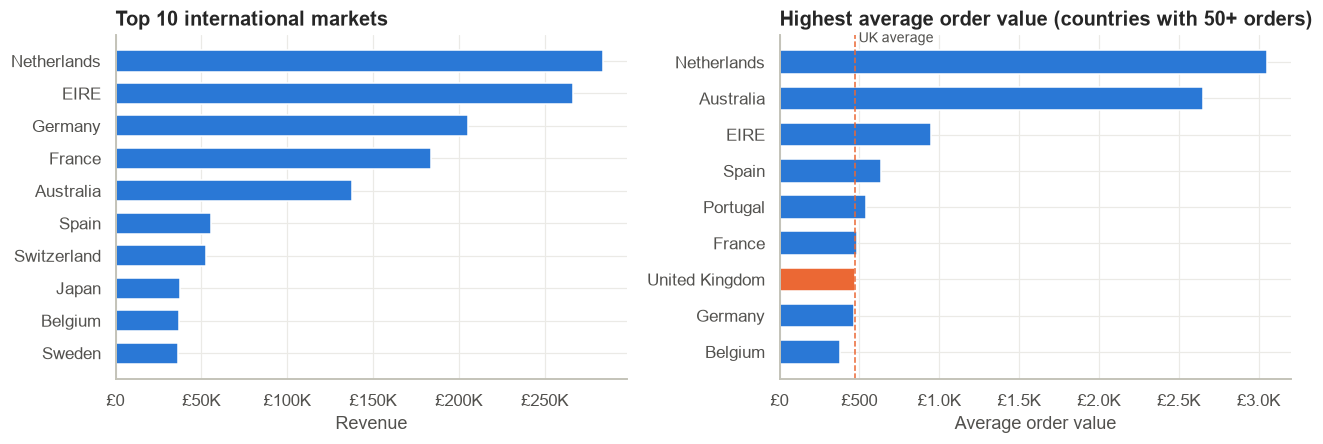

In [19]:
intl = country.drop("United Kingdom").sort_values("Revenue", ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(intl.index[::-1], intl["Revenue"][::-1], color=BLUE, height=0.65)
axes[0].xaxis.set_major_formatter(gbp)
axes[0].set(title="Top 10 international markets", xlabel="Revenue")

aov = country[country["Orders"] >= 50].sort_values("AOV", ascending=False).head(10)
bar_colors = [ORANGE if c == "United Kingdom" else BLUE for c in aov.index[::-1]]
axes[1].barh(aov.index[::-1], aov["AOV"][::-1], color=bar_colors, height=0.65)
axes[1].axvline(country.loc["United Kingdom", "AOV"], color=ORANGE, ls="--", lw=1)
axes[1].text(country.loc["United Kingdom", "AOV"], len(aov) - 0.45, " UK average", color=INK, fontsize=9)
axes[1].xaxis.set_major_formatter(gbp)
axes[1].set(title="Highest average order value (countries with 50+ orders)", xlabel="Average order value")
plt.tight_layout()
save(fig, "05_countries")
plt.show()

### 3.5 What: products

In [20]:
products = (df.groupby(["StockCode", "Description"])
              .agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"), Orders=("InvoiceNo", "nunique"),
                   AvgPrice=("UnitPrice", "median"))
              .sort_values("Revenue", ascending=False).reset_index())
products["CumShare"] = products["Revenue"].cumsum() / products["Revenue"].sum()
n80 = (products["CumShare"] <= 0.80).sum() + 1
print(f"{n80:,} of {len(products):,} products ({n80 / len(products):.1%}) generate 80% of revenue")
products.head(10)

843 of 3,899 products (21.6%) generate 80% of revenue


,StockCode,Description,Revenue,Units,Orders,AvgPrice,CumShare
0,22423,REGENCY CAKESTAND 3 TIER,"172,821.54",13735,1979,12.75,0.02
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"103,152.35",37129,2196,2.95,0.03
2,47566,PARTY BUNTING,"99,425.43",18279,1684,4.95,0.04
3,85099B,JUMBO BAG RED RETROSPOT,"92,683.13",47530,2082,2.08,0.05
4,23084,RABBIT NIGHT LIGHT,"66,857.55",30733,993,2.08,0.05
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"63,933.99",18961,1152,2.95,0.06
6,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,905.65",36349,1453,1.69,0.07
7,79321,CHILLI LIGHTS,"53,767.36",10226,659,5.75,0.07
8,22197,POPCORN HOLDER,"51,181.97",56688,1390,0.85,0.08
9,23298,SPOTTY BUNTING,"43,128.38",8462,1145,4.95,0.08


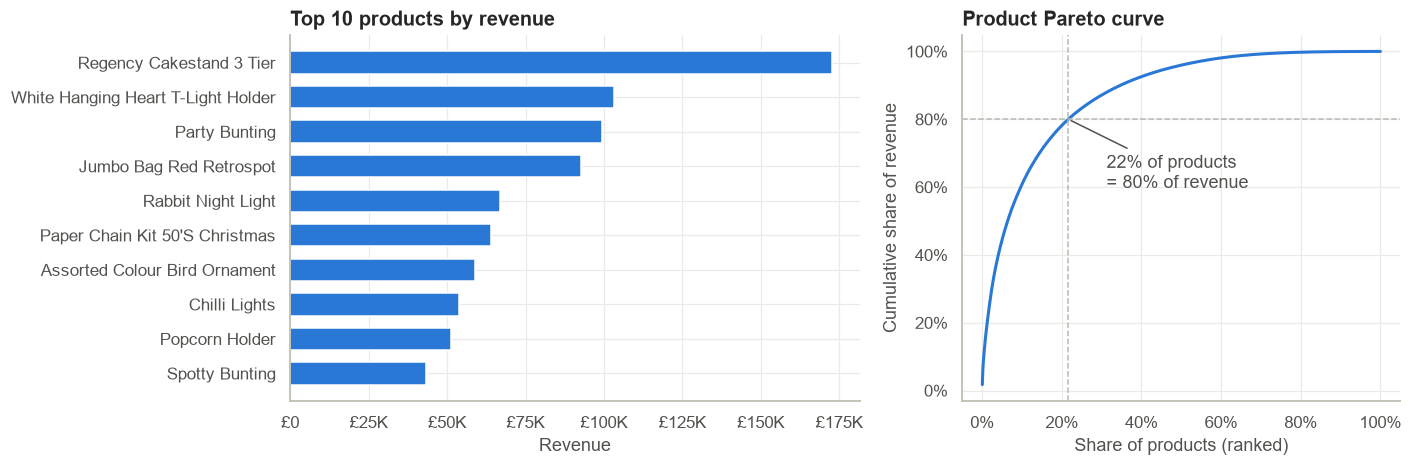

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
top = products.head(10)
axes[0].barh(top["Description"].str.title()[::-1], top["Revenue"][::-1], color=BLUE, height=0.65)
axes[0].xaxis.set_major_formatter(gbp)
axes[0].set(title="Top 10 products by revenue", xlabel="Revenue")

x = np.arange(1, len(products) + 1) / len(products)
axes[1].plot(x, products["CumShare"], color=BLUE)
axes[1].axhline(0.8, color=MUTED, lw=1, ls="--")
axes[1].axvline(n80 / len(products), color=MUTED, lw=1, ls="--")
axes[1].annotate(f"{n80 / len(products):.0%} of products\n= 80% of revenue", xy=(n80 / len(products), 0.8),
                 xytext=(25, -45), textcoords="offset points", color=INK, arrowprops=dict(arrowstyle="-", color=INK))
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set(title="Product Pareto curve", xlabel="Share of products (ranked)", ylabel="Cumulative share of revenue")
plt.tight_layout()
save(fig, "06_products")
plt.show()

### 3.6 Who: customers and RFM segments

Customer-level analysis uses only rows **with** a CustomerID.

In [22]:
snapshot = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
known = df[df["HasCustomer"]]
cust = known.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    Units=("Quantity", "sum"),
    Tenure=("InvoiceDate", lambda s: (snapshot - s.min()).days),
    Country=("Country", "first"),
)
cust["AvgOrderValue"] = cust["Monetary"] / cust["Frequency"]
cust["UnitsPerOrder"] = cust["Units"] / cust["Frequency"]

cust = cust.sort_values("Monetary", ascending=False)
cum = cust["Monetary"].cumsum() / cust["Monetary"].sum()
top20 = cust["Monetary"].head(int(len(cust) * 0.2)).sum() / cust["Monetary"].sum()
print(f"{len(cust):,} customers | top 20% generate {top20:.1%} of their revenue | "
      f"top 10 customers: {cust['Monetary'].head(10).sum() / cust['Monetary'].sum():.1%}")
print(f"One-time buyers: {(cust['Frequency'] == 1).mean():.1%} of customers")
cust.describe().T[["mean", "50%", "max"]]

4,333 customers | top 20% generate 73.7% of their revenue | top 10 customers: 16.5%
One-time buyers: 34.8% of customers


,mean,50%,max
Recency,92.34,50.00,373.00
Frequency,4.23,2.00,202.00
Monetary,"1,938.55",658.64,"279,138.02"
UniqueProducts,61.40,35.00,"1,785.00"
Units,"1,144.07",376.00,"196,844.00"
Tenure,222.80,248.00,373.00
AvgOrderValue,375.59,289.45,"14,844.77"
UnitsPerOrder,228.90,160.80,"7,824.00"


In [23]:
# RFM scores 1-5 by quintile (rank first so ties don't break qcut)
r = pd.qcut(cust["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
f = pd.qcut(cust["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
m = pd.qcut(cust["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust = cust.assign(R=r, F=f, M=m)

def segment(row):
    if row.R >= 4 and row.F >= 4 and row.M >= 4: return "Champions"
    if row.R >= 3 and row.F >= 3:                return "Loyal"
    if row.R >= 4 and row.F <= 2:                return "New / Promising"
    if row.R <= 2 and row.F >= 3:                return "At Risk"
    if row.R <= 2 and row.F <= 2:                return "Lost / Hibernating"
    return "Needs Attention"

cust["Segment"] = cust.apply(segment, axis=1)
order = ["Champions", "Loyal", "New / Promising", "Needs Attention", "At Risk", "Lost / Hibernating"]
seg = (cust.groupby("Segment").agg(Customers=("Monetary", "size"), Revenue=("Monetary", "sum"),
                                   AvgRecency=("Recency", "median"), AvgOrders=("Frequency", "median"))
           .reindex(order))
seg["% Customers"] = 100 * seg["Customers"] / seg["Customers"].sum()
seg["% Revenue"] = 100 * seg["Revenue"] / seg["Revenue"].sum()
seg

,Customers,Revenue,AvgRecency,AvgOrders,% Customers,% Revenue
Segment,,,,,,
Champions,902,"5,537,417.09",9.50,8.00,20.82,65.92
Loyal,1042,"1,302,642.04",31.00,3.00,24.05,15.51
New / Promising,300,"160,089.50",18.00,1.00,6.92,1.91
Needs Attention,356,"196,090.49",52.00,1.00,8.22,2.33
At Risk,656,"705,217.56",134.00,3.00,15.14,8.40
Lost / Hibernating,1077,"498,259.70",218.00,1.00,24.86,5.93


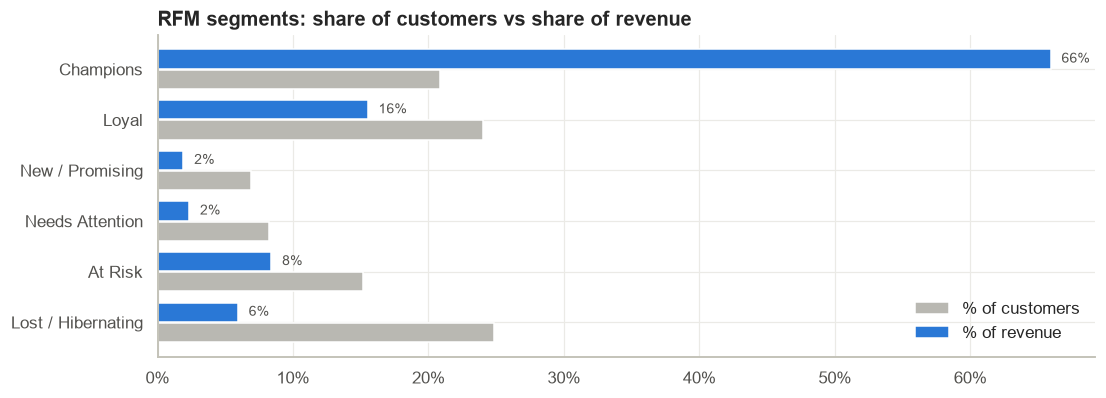

In [24]:
fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(seg))
ax.barh(y + 0.2, seg["% Customers"], height=0.38, color=MUTED, label="% of customers")
ax.barh(y - 0.2, seg["% Revenue"], height=0.38, color=BLUE, label="% of revenue")
for yi, v in zip(y - 0.2, seg["% Revenue"]):
    ax.text(v + 0.8, yi, f"{v:.0f}%", va="center", color=INK, fontsize=9)
ax.set_yticks(y, seg.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="lower right", frameon=False)
ax.set(title="RFM segments: share of customers vs share of revenue", xlabel="")
save(fig, "07_rfm_segments")
plt.show()

### 3.7 Relationships between variables

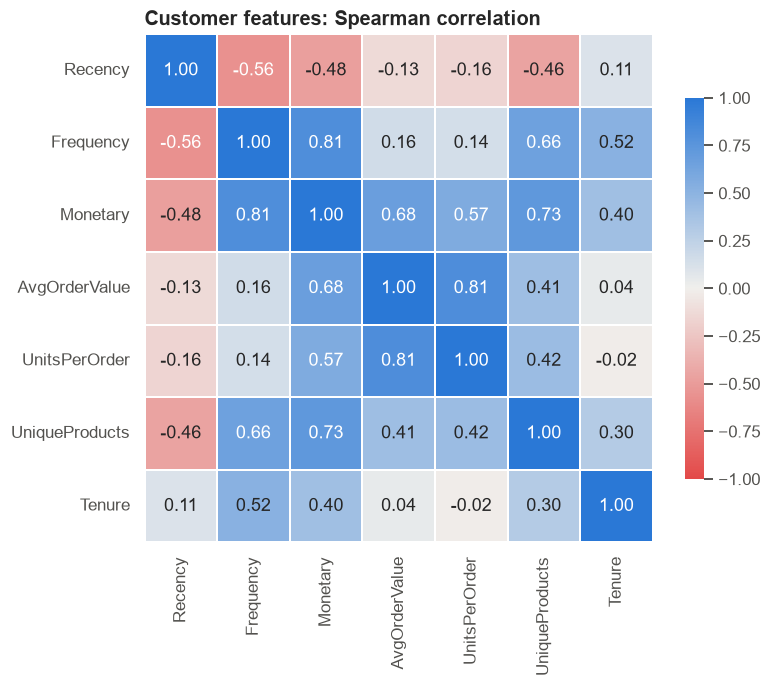

In [25]:
features = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "UnitsPerOrder", "UniqueProducts", "Tenure"]
corr = cust[features].corr(method="spearman")      # rank-based: robust to the heavy skew seen in 3.1
fig, ax = plt.subplots(figsize=(7.5, 6))
div = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
sns.heatmap(corr, annot=True, fmt=".2f", cmap=div, vmin=-1, vmax=1, center=0, square=True,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax)
ax.set(title="Customer features: Spearman correlation")
save(fig, "08_correlation")
plt.show()

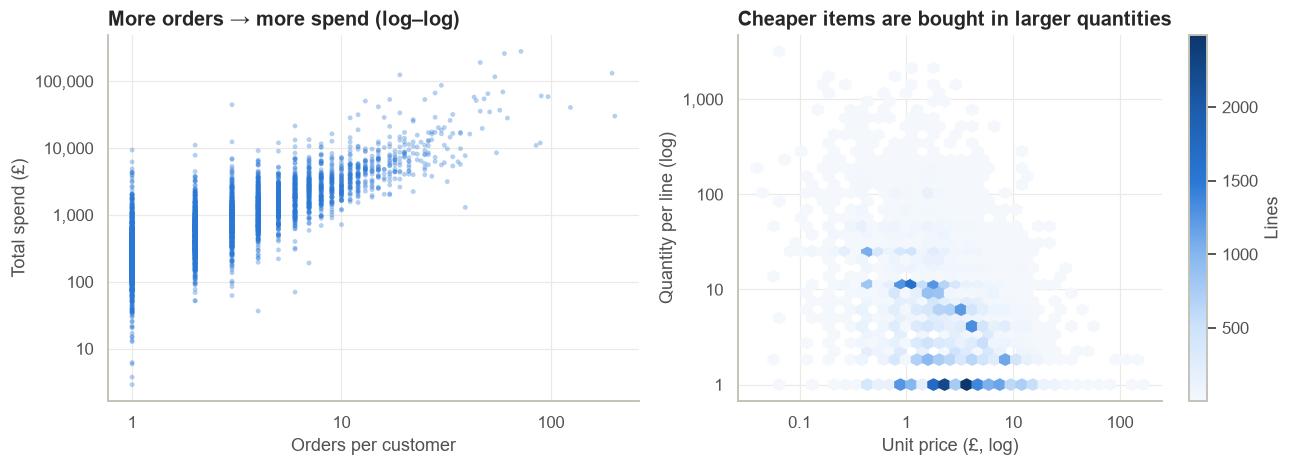

Spearman correlation, unit price vs quantity per line: -0.41


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].scatter(cust["Frequency"], cust["Monetary"], s=10, alpha=0.35, color=BLUE, edgecolors="none")
axes[0].set(xscale="log", yscale="log", title="More orders → more spend (log–log)",
            xlabel="Orders per customer", ylabel="Total spend (£)")
plain = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}")

lines = df.sample(60_000, random_state=1)
hb = axes[1].hexbin(lines["UnitPrice"], lines["Quantity"], xscale="log", yscale="log", gridsize=35, cmap=SEQ, mincnt=1)
axes[1].set(title="Cheaper items are bought in larger quantities", xlabel="Unit price (£, log)", ylabel="Quantity per line (log)")
fig.colorbar(hb, ax=axes[1], label="Lines")
for ax in axes:
    ax.xaxis.set_major_formatter(plain)
    ax.yaxis.set_major_formatter(plain)
plt.tight_layout()
save(fig, "09_relationships")
plt.show()

rho = df[["UnitPrice", "Quantity"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation, unit price vs quantity per line: {rho:.2f}")

### 3.8 Retention: monthly cohorts

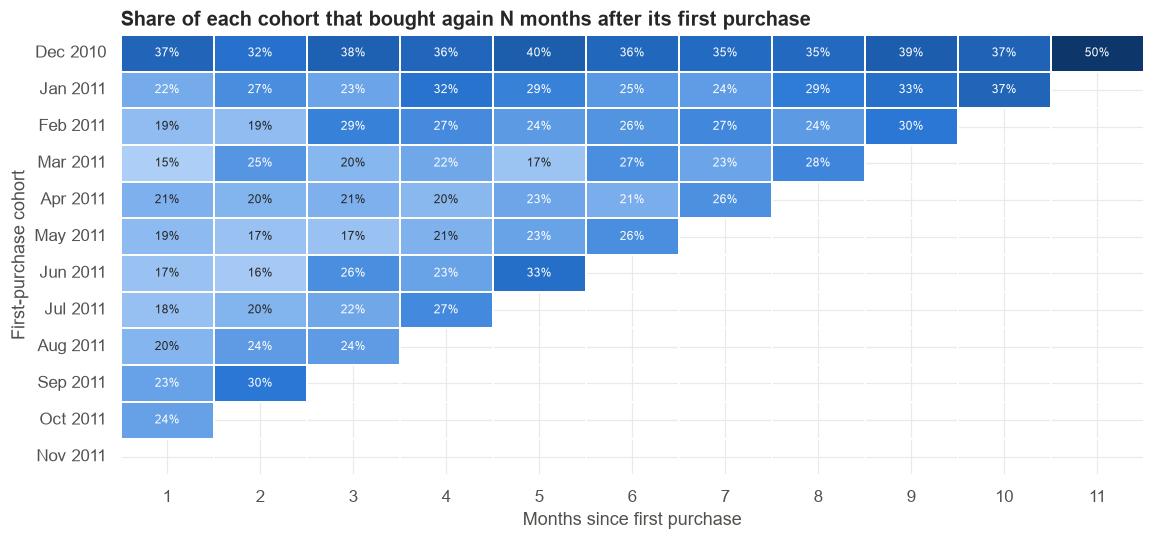

Dec-2010 cohort: 37% came back the next month; later cohorts average 20% in month 1 and 23% in month 3


In [27]:
first = known.groupby("CustomerID")["Month"].min().rename("Cohort")
# December 2011 has only 9 days of data, so it is left out to avoid a false drop in the last column
act = (known.loc[known["Month"] <= pd.Period("2011-11"), ["CustomerID", "Month"]]
            .drop_duplicates().join(first, on="CustomerID"))
act["Age"] = (act["Month"] - act["Cohort"]).apply(lambda d: d.n)
cohort = act.pivot_table(index="Cohort", columns="Age", values="CustomerID", aggfunc="nunique")
retention = cohort.div(cohort[0], axis=0)

fig, ax = plt.subplots(figsize=(12, 5.2))
sns.heatmap(retention.iloc[:, 1:], annot=True, fmt=".0%", cmap=SEQ, vmin=0, vmax=0.5,
            linewidths=1, linecolor="white", cbar=False, annot_kws={"fontsize": 8}, ax=ax)
ax.set_yticklabels([p.strftime("%b %Y") for p in retention.index], rotation=0)
ax.set(title="Share of each cohort that bought again N months after its first purchase",
       xlabel="Months since first purchase", ylabel="First-purchase cohort")
save(fig, "10_cohort_retention")
plt.show()

m1 = retention[1].drop(pd.Period("2010-12")).mean()
m3 = retention[3].drop(pd.Period("2010-12")).mean()
print(f"Dec-2010 cohort: {retention.loc['2010-12', 1]:.0%} came back the next month; "
      f"later cohorts average {m1:.0%} in month 1 and {m3:.0%} in month 3")

### 3.9 Returns

In [28]:
ret_value = -returns["Revenue"].sum()
print(f"Returned value: £{ret_value:,.0f} = {ret_value / df['Revenue'].sum():.1%} of sales value; "
      f"{returns['InvoiceNo'].nunique():,} cancellation invoices")

ret_prod = (returns.groupby("StockCode").agg(ReturnedValue=("Revenue", lambda s: -s.sum()),
                                              ReturnedUnits=("Quantity", lambda s: -s.sum()))
            .join(products.set_index("StockCode")[["Description", "Revenue", "Units"]], how="inner"))
ret_prod["ReturnRateUnits"] = ret_prod["ReturnedUnits"] / ret_prod["Units"]
ret_prod.query("Units >= 500").sort_values("ReturnedValue", ascending=False).head(8)

Returned value: £183,100 = 1.8% of sales value; 3,277 cancellation invoices


,ReturnedValue,ReturnedUnits,Description,Revenue,Units,ReturnRateUnits
StockCode,,,,,,
22423,"8,365.65",739,REGENCY CAKESTAND 3 TIER,"172,821.54",13735,0.05
21108,"6,553.62",3132,FAIRY CAKE FLANNEL ASSORTED COLOUR,"18,018.48",10223,0.31
85123A,"5,313.90",2066,WHITE HANGING HEART T-LIGHT HOLDER,"103,152.35",37129,0.06
48185,"4,554.90",674,DOORMAT FAIRY CAKE,"23,872.91",3615,0.19
21175,"3,744.73",2018,GIN + TONIC DIET METAL SIGN,"26,999.37",12195,0.17
22273,"3,512.65",1447,FELTCRAFT DOLL MOLLY,"12,001.59",4509,0.32
47566B,"3,505.45",1374,TEA TIME PARTY BUNTING,"11,087.77",2329,0.59
71477,"3,364.66",1204,COLOUR GLASS. STAR T-LIGHT HOLDER,"20,571.70",6724,0.18


In [29]:
ret_country = (returns.groupby("Country")["Revenue"].sum().mul(-1).rename("Returned")
               .to_frame().join(country["Revenue"]))
ret_country["ReturnRate"] = ret_country["Returned"] / ret_country["Revenue"]
ret_country.query("Revenue >= 50_000").sort_values("ReturnRate", ascending=False).head(8)

,Returned,Revenue,ReturnRate
Country,,,
Spain,"3,959.91","55,706.56",0.07
EIRE,"6,937.34","266,317.36",0.03
Germany,"4,749.59","205,369.25",0.02
United Kingdom,"156,422.43","8,392,779.72",0.02
France,"1,710.94","183,787.54",0.01
Switzerland,399.40,"52,881.65",0.01
Australia,879.71,"137,727.21",0.01
Netherlands,409.80,"283,889.34",0.00


## 4. Key findings and recommendations

### Data quality
- **96.3% of rows kept** (541,909 → 521,819) after 7 documented cleaning steps. The largest issues were cancellations (9,251 rows),
  duplicates (5,268) and non-product codes such as postage and fees (2,406).
- Two orders of **80,995 and 74,215 units** were cancelled 12–16 minutes later. Left in, they would add about £246K of fake sales
  and make two minor products the best sellers by units.
- **25% of rows have no CustomerID** but only 16.5% of sales value. Dropping them, as many tutorials do, would under-state revenue.
  They are kept for revenue analysis and excluded only from customer-level work.

### Findings
| # | Finding | Evidence |
|---|---|---|
| 1 | **Strong Q4 seasonality**: Sep–Nov 2011 brought in 35.8% of the year's revenue. November alone was £1.44M | 3.2 |
| 2 | **Growth comes from more customers, not bigger baskets**: Nov-2011 vs Dec-2010 shows customers +88% and revenue +87%, but average order value only +5% | 3.2 |
| 3 | **A B2B weekday pattern**: no orders at all on Saturday, Sunday is only 8% of revenue, and most revenue lands on weekdays between 10:00 and 15:00 | 3.3 |
| 4 | **UK = 85% of revenue.** Abroad, a handful of wholesale accounts dominate: the Netherlands brings £284K from just 9 customers (average order £3,053, 6.5× the UK) | 3.4 |
| 5 | **The long tail is real**: 22% of the 3,899 products generate 80% of revenue | 3.5 |
| 6 | **Customers are concentrated**: the top 20% generate 74% of revenue. "Champions" (21% of customers) bring 66%. 35% of customers bought only once | 3.6 |
| 7 | **£705K sits with "At Risk" customers** (15% of customers): they used to buy regularly but have been inactive for a median of 134 days | 3.6 |
| 8 | **Spend has two independent drivers**: *how often* (frequency ↔ spend ρ = 0.81) and *how big* (order value ↔ units per order ρ = 0.81). Frequency and order value are almost unrelated (ρ = 0.16) | 3.7 |
| 9 | **Price vs quantity**: cheaper items are bought in bulk (ρ = −0.41 between unit price and quantity per line), a typical wholesale pattern | 3.7 |
| 10 | **Retention is the main weakness**: only about 20% of a new cohort buys again the next month (23% by month 3). The Dec-2010 cohort looks better (37%) because it contains existing customers whose history starts before the dataset (left-censoring) | 3.8 |
| 11 | **Returns are low overall (1.8% of sales value) but concentrated**: Tea Time Party Bunting had 59% of its units returned, and Feltcraft Doll Molly and Fairy Cake Flannel about 31–32% | 3.9 |

### Recommendations
1. **Plan stock, staff and cash flow for Sep–Nov.** Place orders for the top 22% of products by August at the latest.
2. **Build a retention programme for first-time buyers**, for example a follow-up offer 30 days after the first order. Raising month-1 retention
   from 20% to 25% is worth more than any single campaign, because 35% of customers never come back.
3. **Win back the At-Risk segment** (656 customers, £705K in past spend) with personal outreach, since many are wholesalers.
4. **Grow international wholesale deliberately.** A single Dutch or Australian account is worth dozens of UK retail customers.
   Give key accounts dedicated account management.
5. **Investigate the high-return products** (quality, description, photos) before the next season.
6. **Fix data capture at the source**: make CustomerID mandatory for online orders, and block orders above a quantity limit without a confirmation step.

### Limitations
- Only 12 months of data, so year-over-year seasonality cannot be confirmed.
- December 2011 is partial (1–9 Dec) and is flagged in all monthly views.
- Only revenue is available (no cost), so profitability cannot be analysed.